<a href="https://colab.research.google.com/github/rishabhucb/court-keypoints/blob/main/day6_final_model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')
import os, glob, shutil, yaml

PROJECT_DIR = '/content/drive/MyDrive/court_keypoints'
OLD = f'{PROJECT_DIR}/court_v4'          # old dataset (labels already fixed, 13 points)
NEW = f'{PROJECT_DIR}/hs_court_clean'    # new dataset (cleaned, 18 points)
DST = f'{PROJECT_DIR}/court_unified'
NK = 24

# Old point ID -> unified ID (only the reliable old points)
OLD_TO_LEFT  = {3: 2,  4: 3,  6: 6,  5: 7,  8: 18, 9: 19, 10: 20}
OLD_TO_RIGHT = {3: 12, 4: 13, 6: 16, 5: 17, 8: 21, 9: 22, 10: 23}

def convert_old(line):
    v = line.split()
    kp = [float(x) for x in v[5:]]
    pts = {i: kp[3*i:3*i+3] for i in range(13)}
    base = [pts[i][0] for i in (3, 4) if pts[i][2] > 0]   # paint corners on the baseline
    ft   = [pts[i][0] for i in (5, 6) if pts[i][2] > 0]   # free-throw line ends
    left = (sum(base)/len(base) < sum(ft)/len(ft)) if base and ft else True
    out = [0.0] * (3 * NK)
    for o, u in (OLD_TO_LEFT if left else OLD_TO_RIGHT).items():
        if pts[o][2] > 0:
            out[3*u:3*u+3] = pts[o]
    return ' '.join(['0'] + v[1:5] + [f'{x:.6f}' for x in out])

def convert_new(line):
    v = line.split()
    return ' '.join(['0'] + v[1:] + ['0.000000'] * (3 * (NK - 18)))   # pad 18 -> 24 points

def copy_split(src, split, dst_split, prefix, convert):
    os.makedirs(f'{DST}/{dst_split}/images', exist_ok=True)
    os.makedirs(f'{DST}/{dst_split}/labels', exist_ok=True)
    n = 0
    for img in glob.glob(f'{src}/{split}/images/*'):
        stem = os.path.splitext(os.path.basename(img))[0]
        lbl = f'{src}/{split}/labels/{stem}.txt'
        if not os.path.exists(lbl):
            continue
        ext = os.path.splitext(img)[1]
        shutil.copy(img, f'{DST}/{dst_split}/images/{prefix}{stem}{ext}')
        lines = [convert(l) for l in open(lbl) if l.strip()]
        open(f'{DST}/{dst_split}/labels/{prefix}{stem}.txt', 'w').write('\n'.join(lines) + '\n')
        n += 1
    return n

shutil.rmtree(DST, ignore_errors=True)
for split in ['train', 'valid']:
    a = copy_split(OLD, split, split, 'old_', convert_old)
    b = copy_split(NEW, split, split, 'new_', convert_new)
    print(f"{split}: {a} old + {b} new = {a + b}")
a = copy_split(OLD, 'test', 'test_old', 'old_', convert_old)
b = copy_split(NEW, 'test', 'test_new', 'new_', convert_new)
print(f"test: {a} old (test_old) + {b} new (test_new)")

FLIP = [10, 11, 12, 13, 14, 15, 16, 17, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 21, 22, 23, 18, 19, 20]
base_cfg = {'path': DST, 'train': 'train/images', 'val': 'valid/images',
            'nc': 1, 'names': ['court'], 'kpt_shape': [NK, 3], 'flip_idx': FLIP}
for name, test in [('data', ['test_old/images', 'test_new/images']),
                   ('data_test_old', 'test_old/images'), ('data_test_new', 'test_new/images')]:
    yaml.safe_dump({**base_cfg, 'test': test}, open(f'{DST}/{name}.yaml', 'w'))
print("Done:", os.listdir(DST))

In [ ]:
import cv2, random, matplotlib.pyplot as plt
for prefix in ['old_', 'new_']:
    lbl = random.choice(glob.glob(f'{DST}/train/labels/{prefix}*.txt'))
    img_path = glob.glob(lbl.replace('/labels/', '/images/').rsplit('.', 1)[0] + '.*')[0]
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB); h, w = img.shape[:2]
    v = list(map(float, open(lbl).readline().split()))[5:]
    for i in range(NK):
        if v[3*i+2] > 0:
            x, y = int(v[3*i]*w), int(v[3*i+1]*h)
            cv2.circle(img, (x, y), 6, (255, 0, 0), -1)
            cv2.putText(img, str(i), (x+8, y-8), cv2.FONT_HERSHEY_SIMPLEX, 0.9, (255, 255, 0), 3)
    plt.figure(figsize=(14, 8)); plt.imshow(img); plt.title(prefix); plt.axis('off'); plt.show()

In [ ]:
from ultralytics import YOLO

DATA_U = f'{PROJECT_DIR}/court_unified/data.yaml'

model = YOLO('yolo11s-pose.pt')      # "s" = a bit bigger than before, for better accuracy
model.train(
    data=DATA_U,
    epochs=120,
    imgsz=640,
    batch=16,
    fliplr=0.5,                      # safe: flip_idx swaps the two baskets correctly
    patience=40,
    project=f'{PROJECT_DIR}/runs',
    name='final_v1',
)

In [ ]:
final = YOLO(f'{PROJECT_DIR}/runs/final_v1/weights/best.pt')
for name in ['data_test_old', 'data_test_new']:
    m = final.val(data=f'{PROJECT_DIR}/court_unified/{name}.yaml', split='test', verbose=False)
    print(f"{name}: pose mAP50 = {m.pose.map50:.3f} | pose mAP50-95 = {m.pose.map:.3f}")

In [ ]:
import json, glob, os, shutil, numpy as np, cv2

U   = f'{PROJECT_DIR}/court_unified'
REL = f'{PROJECT_DIR}/court_detection_release'
os.makedirs(f'{REL}/weights', exist_ok=True)

LEFT  = {'corner_far': 0, 'c3_far': 1, 'paint_far': 2, 'paint_near': 3, 'c3_near': 4, 'corner_near': 5,
         'ft_far': 6, 'ft_near': 7, 'half_far': 8, 'half_near': 9, 'wing_far': 18, 'arc_top': 19, 'wing_near': 20}
RIGHT = {'corner_far': 10, 'c3_far': 11, 'paint_far': 12, 'paint_near': 13, 'c3_near': 14, 'corner_near': 15,
         'ft_far': 16, 'ft_near': 17, 'half_far': 8, 'half_near': 9, 'wing_far': 21, 'arc_top': 22, 'wing_near': 23}
REF = {'paint_far': (19, 0), 'paint_near': (31, 0), 'ft_far': (19, 19), 'ft_near': (31, 19)}  # 12-ft paint, FT line at 19 ft

# Measure every point in "basket feet" (x across the court, y from that basket's baseline)
samples = {k: [] for k in LEFT}
for lbl in glob.glob(f'{U}/train/labels/*.txt') + glob.glob(f'{U}/valid/labels/*.txt'):
    for line in open(lbl):
        v = [float(x) for x in line.split()[5:]]
        for side in (LEFT, RIGHT):
            if not all(v[3*side[k]+2] > 0 for k in REF):
                continue
            Hb = cv2.getPerspectiveTransform(np.float32([v[3*side[k]:3*side[k]+2] for k in REF]),
                                             np.float32(list(REF.values())))
            for name, i in side.items():
                if v[3*i+2] > 0:
                    samples[name].append(cv2.perspectiveTransform(np.float32([[v[3*i:3*i+2]]]), Hb)[0, 0])

local, spread = {}, {}
print(f"{'point':12s} {'x ft':>7s} {'y ft':>7s} {'spread':>7s} {'n':>5s}")
for k, s in samples.items():
    if len(s) < 10:
        print(f"{k:12s} too few samples ({len(s)})"); continue
    a = np.array(s); med = np.median(a, 0)
    local[k], spread[k] = med, float(np.median(np.hypot(*(a - med).T)))
    print(f"{k:12s} {med[0]:7.2f} {med[1]:7.2f} {spread[k]:7.2f} {len(a):5d}")

# 3-point line: circle through the 3 arc points + straight corner lines at the corner-3 points
P = np.array([local[k] for k in ['wing_far', 'arc_top', 'wing_near']])
cx, cy, c = np.linalg.solve(np.c_[2 * P, np.ones(3)], (P ** 2).sum(1))
R = float(np.sqrt(c + cx ** 2 + cy ** 2))
xc1, xc2 = float(local['c3_far'][0]), float(local['c3_near'][0])
print(f"\n3-point arc: center ({cx:.2f}, {cy:.2f}) ft, radius {R:.2f} ft | corner lines at x = {xc1:.2f} / {xc2:.2f} ft")
print(f"Half-court measured at y = {np.mean([local['half_far'][1], local['half_near'][1]]):.1f} ft (expected ~42)")

# Full-court positions (84 x 50 ft high-school court), right basket mirrored
L, Wd = 84.0, 50.0
kp_ft = {}
for k, i in LEFT.items():
    if k in local and not k.startswith('half'):
        kp_ft[i] = [float(local[k][0]), float(local[k][1])]
for k, i in RIGHT.items():
    if k in local and not k.startswith('half'):
        kp_ft[i] = [float(local[k][0]), float(L - local[k][1])]
for k in ['half_far', 'half_near']:
    if k in local:
        kp_ft[LEFT[k]] = [float(local[k][0]), L / 2]

id_name = {**{i: k for k, i in LEFT.items()}, **{i: k for k, i in RIGHT.items()}}
use_ids = sorted(i for i in kp_ft if spread[id_name[i]] < 2.0)     # only consistently-labeled points
print("Points used for the homography:", use_ids)

cfg = {'court_length_ft': L, 'court_width_ft': Wd,
       'keypoints_ft': {str(i): kp_ft.get(i) for i in range(24)},
       'use_ids': use_ids,
       'three_point': {'center': [float(cx), float(cy)], 'radius': R, 'corner_x': [xc1, xc2]},
       'margin_ft': 1.5,
       'flip_idx': [10, 11, 12, 13, 14, 15, 16, 17, 8, 9, 0, 1, 2, 3, 4, 5, 6, 7, 21, 22, 23, 18, 19, 20]}
json.dump(cfg, open(f'{REL}/court_config.json', 'w'), indent=2)
shutil.copy(f'{PROJECT_DIR}/runs/final_v1/weights/best.pt', f'{REL}/weights/court_model.pt')
print("\nSaved court_config.json and weights/court_model.pt")

In [ ]:
%%writefile /content/drive/MyDrive/court_keypoints/court_detection_release/court_detector.py
"""NextRun court detection.

Image -> 24 court keypoints (YOLO11s-pose) -> homography -> court position in feet -> 2PT / 3PT.
Court frame (feet): x across the court (0 = far sideline, 50 = near sideline),
                    y along the court (0 = left baseline, 84 = right baseline).
"""
import json
import numpy as np
import cv2
from ultralytics import YOLO


class CourtDetector:
    def __init__(self, weights='weights/court_model.pt', config='court_config.json', conf_th=0.5):
        self.model = YOLO(weights)
        cfg = json.load(open(config))
        self.L, self.W = cfg['court_length_ft'], cfg['court_width_ft']
        self.kp_ft = {int(k): v for k, v in cfg['keypoints_ft'].items() if v is not None}
        self.use_ids = cfg['use_ids']
        tp = cfg['three_point']
        self.cx, self.cy = tp['center']
        self.R = tp['radius']
        self.xc1, self.xc2 = tp['corner_x']
        self.margin = cfg['margin_ft']
        self.conf_th = conf_th

    def keypoints(self, frame):
        """(xy [24 x 2] pixels, confidence [24]) of the best court detection, or (None, None)."""
        r = self.model.predict(frame, conf=0.25, verbose=False)[0]
        if r.keypoints is None or len(r.boxes) == 0:
            return None, None
        b = int(r.boxes.conf.argmax())
        return r.keypoints.xy[b].cpu().numpy(), r.keypoints.conf[b].cpu().numpy()

    def homography(self, frame):
        """3x3 matrix mapping image pixels -> court feet, or None if the court isn't found."""
        xy, kc = self.keypoints(frame)
        if xy is None:
            return None
        ids = [i for i in self.use_ids if i in self.kp_ft and kc[i] > self.conf_th]
        if len(ids) < 4:
            return None
        H, _ = cv2.findHomography(np.float32([xy[i] for i in ids]),
                                  np.float32([self.kp_ft[i] for i in ids]), cv2.RANSAC, 1.5)
        return H

    @staticmethod
    def to_court(H, points_px):
        """Image pixels [(x, y), ...] -> court feet [(x_ft, y_ft), ...]."""
        pts = np.float32(points_px).reshape(-1, 1, 2)
        return cv2.perspectiveTransform(pts, H).reshape(-1, 2)

    def _join_y(self, xc):
        return self.cy + np.sqrt(max(self.R ** 2 - (xc - self.cx) ** 2, 0.0))

    def distance_to_three_point_line(self, x_ft, y_ft):
        """Signed distance (ft) to the nearer basket's 3-point line: + outside (3PT), - inside (2PT)."""
        y = y_ft if y_ft <= self.L / 2 else self.L - y_ft
        xc = self.xc1 if x_ft < self.cx else self.xc2
        if y < self._join_y(xc):                       # corner: straight line
            return max(self.xc1 - x_ft, x_ft - self.xc2)
        return float(np.hypot(x_ft - self.cx, y - self.cy) - self.R)

    def shot_zone(self, x_ft, y_ft):
        """'2PT', '3PT', or 'CLOSE' (within margin_ft of the line, too close to call)."""
        d = self.distance_to_three_point_line(x_ft, y_ft)
        if abs(d) < self.margin:
            return 'CLOSE'
        return '3PT' if d > 0 else '2PT'

    def three_point_lines_ft(self, n=100):
        """Both 3-point lines as polylines in court feet: [left, right]."""
        y1, y2 = self._join_y(self.xc1), self._join_y(self.xc2)
        a1 = np.arctan2(y1 - self.cy, self.xc1 - self.cx)
        a2 = np.arctan2(y2 - self.cy, self.xc2 - self.cx)
        arc = [(self.cx + self.R * np.cos(a), self.cy + self.R * np.sin(a)) for a in np.linspace(a1, a2, n)]
        left = np.array([(self.xc1, 0.0)] + arc + [(self.xc2, 0.0)], float)
        right = left.copy()
        right[:, 1] = self.L - right[:, 1]
        return [left, right]

    def draw_three_point_lines(self, frame, H, color=(0, 215, 255), thickness=3):
        """Draw both 3-point lines onto the camera image (in place)."""
        h, w = frame.shape[:2]
        Hinv = np.linalg.inv(H)
        ref = self.to_court(H, [(w / 2, h - 1)])[0]                   # a floor point surely in view
        ref_sign = np.sign((Hinv @ [ref[0], ref[1], 1.0])[2])
        for line in self.three_point_lines_ft():
            P = np.c_[line, np.ones(len(line))] @ Hinv.T
            ok = np.sign(P[:, 2]) == ref_sign                        # drop points "behind" the camera
            px = P[:, :2] / P[:, 2:3]
            run = []
            for p, good in zip(px, ok):
                if good and np.all(np.abs(p) < 1e5):
                    run.append(p)
                else:
                    if len(run) > 1:
                        cv2.polylines(frame, [np.int32(run)], False, color, thickness)
                    run = []
            if len(run) > 1:
                cv2.polylines(frame, [np.int32(run)], False, color, thickness)
        return frame

In [ ]:
%%writefile /content/drive/MyDrive/court_keypoints/court_detection_release/demo.py
"""Demo:  python demo.py --source game.mp4 --output out.mp4     (or --source frame.jpg)"""
import argparse
import cv2
import numpy as np
from ultralytics import YOLO
from court_detector import CourtDetector

COLORS = {'2PT': (214, 120, 42), '3PT': (52, 104, 235), 'CLOSE': (160, 160, 160)}   # blue, orange, gray
YELLOW, WHITE = (0, 215, 255), (255, 255, 255)


def minimap(det, players, scale=6, m=10):
    W, L = det.W, det.L
    img = np.full((int(W * scale) + 2 * m, int(L * scale) + 2 * m, 3), (80, 140, 190), np.uint8)
    P = lambda x, y: (int(m + y * scale), int(m + x * scale))
    cv2.rectangle(img, P(0, 0), P(W, L), WHITE, 2)
    cv2.line(img, P(0, L / 2), P(W, L / 2), WHITE, 2)
    for y0, y1 in [(0, 19), (L, L - 19)]:
        cv2.rectangle(img, P(19, y0), P(31, y1), WHITE, 2)
    for line in det.three_point_lines_ft():
        cv2.polylines(img, [np.int32([P(x, y) for x, y in line])], False, YELLOW, 2)
    for (x, y), z in players:
        cv2.circle(img, P(x, y), 6, COLORS[z], -1)
    return img


def annotate(frame, det, H, person_model):
    out, players = frame.copy(), []
    if H is not None:
        det.draw_three_point_lines(out, H)
        boxes = person_model.predict(frame, classes=[0], conf=0.4, verbose=False)[0].boxes.xyxy.cpu().numpy()
        for b in boxes:
            x, y = det.to_court(H, [((b[0] + b[2]) / 2, b[3])])[0]       # feet = bottom-center of the box
            if not (0 <= x <= det.W and 0 <= y <= det.L):
                continue                                                 # off the court (bench, fans)
            z = det.shot_zone(x, y)
            players.append(((x, y), z))
            c = COLORS[z]
            cv2.rectangle(out, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), c, 2)
            cv2.putText(out, z, (int(b[0]), int(b[1]) - 6), cv2.FONT_HERSHEY_SIMPLEX, 0.7, c, 2)
    mm = minimap(det, players)
    h, w = out.shape[:2]
    s = min(0.35 * w / mm.shape[1], 1.0)
    mm = cv2.resize(mm, (int(mm.shape[1] * s), int(mm.shape[0] * s)))
    out[h - mm.shape[0] - 10:h - 10, w - mm.shape[1] - 10:w - 10] = mm
    return out


def main():
    ap = argparse.ArgumentParser()
    ap.add_argument('--source', required=True)
    ap.add_argument('--output', default='demo_out')
    ap.add_argument('--weights', default='weights/court_model.pt')
    ap.add_argument('--config', default='court_config.json')
    ap.add_argument('--every', type=int, default=5, help='re-detect the court every N video frames')
    a = ap.parse_args()

    det, person = CourtDetector(a.weights, a.config), YOLO('yolo11n.pt')
    if a.source.lower().endswith(('.jpg', '.jpeg', '.png')):
        frame = cv2.imread(a.source)
        out = annotate(frame, det, det.homography(frame), person)
        path = a.output if a.output.lower().endswith(('.jpg', '.png')) else a.output + '.jpg'
        cv2.imwrite(path, out)
        print('Saved', path)
        return

    cap = cv2.VideoCapture(a.source)
    fps = cap.get(cv2.CAP_PROP_FPS) or 30
    path = a.output if a.output.endswith('.mp4') else a.output + '.mp4'
    writer, H, n = None, None, 0
    while True:
        ok, frame = cap.read()
        if not ok:
            break
        if n % a.every == 0:
            H_new = det.homography(frame)
            if H_new is not None:
                H = H_new
        out = annotate(frame, det, H, person)
        if writer is None:
            writer = cv2.VideoWriter(path, cv2.VideoWriter_fourcc(*'mp4v'), fps, (out.shape[1], out.shape[0]))
        writer.write(out)
        n += 1
    cap.release()
    if writer:
        writer.release()
    print(f'Saved {path} ({n} frames)')


if __name__ == '__main__':
    main()

In [ ]:
%%writefile /content/drive/MyDrive/court_keypoints/court_detection_release/requirements.txt
ultralytics>=8.3
opencv-python
numpy

In [ ]:
%%writefile /content/drive/MyDrive/court_keypoints/court_detection_release/README.md
# Court Detection (NextRun)

Finds basketball court keypoints in a camera frame, maps image pixels to real court
positions in feet (homography), draws the 3-point lines, and classifies positions as 2PT / 3PT.

## Files
| File | What it is |
|---|---|
| `weights/court_model.pt` | YOLO11s-pose model, 24 court keypoints |
| `court_config.json` | Court position (ft) of each keypoint, 3-point line geometry |
| `court_detector.py` | `CourtDetector` class: keypoints, homography, court position, 2PT/3PT |
| `demo.py` | Runs everything on an image or video and draws the result |

## Install
    pip install -r requirements.txt

## Use in code
    from court_detector import CourtDetector
    det = CourtDetector('weights/court_model.pt', 'court_config.json')
    H = det.homography(frame)                    # None if the court isn't found
    x_ft, y_ft = det.to_court(H, [(px, py)])[0]  # e.g. a player's feet or the ball
    det.shot_zone(x_ft, y_ft)                    # '2PT', '3PT' or 'CLOSE'
    det.draw_three_point_lines(frame, H)

## Demo
    python demo.py --source game.mp4 --output out.mp4
    python demo.py --source frame.jpg --output out.jpg

## Court coordinates
x = across the court (0 = far sideline, 50 = near sideline), y = along the court
(0 = left baseline, 84 = right baseline). High-school court, 84 x 50 ft.
Positions in `court_config.json` were measured from the training labels, using the paint (12 ft wide, free-throw line at 19 ft) as reference.

## Keypoints (24)
| IDs | Left basket | IDs | Right basket |
|---|---|---|---|
| 0 / 5 | baseline corners (far / near) | 10 / 15 | same |
| 1 / 4 | corner-3 line meets baseline (far / near) | 11 / 14 | same |
| 2 / 3 | paint corners on baseline (far / near) | 12 / 13 | same |
| 6 / 7 | free-throw line ends (far / near) | 16 / 17 | same |
| 18 / 19 / 20 | 3-point arc: far wing / top / near wing | 21 / 22 / 23 | same |
| 8 / 9 | half-court line at far / near sideline | | |

## Accuracy
See RESULTS section below (filled in after evaluation).

## Limitations
- Trained on high-school gym footage from two camera setups (elevated corner view, elevated sideline view). New camera angles may need more training data.
- Classifies **positions**, not shots: scoring a shot needs ball/hoop detection and player tracking.
- Feet = bottom of the person box; a jumping player's position is off while in the air.

## Data
- Roboflow basketball court keypoints dataset (forked; see the Roboflow project page for its license)
- "HS Basketball - Court Keypoints" by Ethan Liu, Roboflow Universe, CC BY 4.0

In [ ]:
%cd /content/drive/MyDrive/court_keypoints/court_detection_release
import sys, glob, random, cv2, numpy as np
sys.path.insert(0, '.')
from court_detector import CourtDetector
from IPython.display import Image, display

det = CourtDetector('weights/court_model.pt', 'court_config.json')

def mapping_error(split):
    imgs, errs, found = glob.glob(f'{U}/{split}/images/*'), [], 0
    for p in imgs:
        img = cv2.imread(p); h, w = img.shape[:2]
        H = det.homography(img)
        if H is None:
            continue
        found += 1
        v = [float(x) for x in open(p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt').readline().split()[5:]]
        e = [np.hypot(*(det.to_court(H, [(v[3*i]*w, v[3*i+1]*h)])[0] - det.kp_ft[i]))
             for i in det.use_ids if v[3*i+2] > 0]
        if e:
            errs.append(np.mean(e))
    print(f"{split}: court found in {found}/{len(imgs)} images | mapping error mean {np.mean(errs):.2f} ft, median {np.median(errs):.2f} ft")

mapping_error('test_old')
mapping_error('test_new')

srcs = random.sample(glob.glob(f'{U}/test_old/images/*'), 1) + random.sample(glob.glob(f'{U}/test_new/images/*'), 2)
for i, src in enumerate(srcs):
    !python demo.py --source "{src}" --output /content/demo_{i}.jpg
    display(Image(f'/content/demo_{i}.jpg', width=1100))

In [ ]:
open(f'{REL}/README.md', 'a').write("""
## Results (held-out test images)
| Test set | Court found | Pose mAP50 | Pose mAP50-95 | Mapping error, median (mean) |
|---|---|---|---|---|
| Corner view, 11 images | 10/11 | 0.995 | 0.90 | 1.27 ft (1.28 ft) |
| Side view, several gyms, 86 images | 86/86 | 0.995 | 0.91 | 1.45 ft (3.41 ft) |

- Mapping error = distance between where a labeled court point lands after the homography and its true court position.
- Side view: most frames are about 1.5 ft accurate; a few frames have large errors, which raises the mean.
- `CLOSE` = within 1.5 ft of the 3-point line, roughly the mapping error, so too close to call.
- Earlier single-view models failed on the camera angle they were not trained on. Training on both views fixed that.
""")
print(open(f'{REL}/README.md').read()[-800:])

In [ ]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')
import numpy as np, cv2, glob, random, sys, matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from scipy.stats import multivariate_normal
%cd /content/drive/MyDrive/court_keypoints/court_detection_release
sys.path.insert(0, '.')
from court_detector import CourtDetector
det = CourtDetector('weights/court_model.pt', 'court_config.json')

def court_area_mask(shape, H, margin_ft=3, step=1.0):
    """Change 2: where the court (plus a small margin) is in the image, from the homography."""
    h, w = shape[:2]
    xs = np.arange(-margin_ft, det.W + margin_ft + 1e-6, step)
    ys = np.arange(-margin_ft, det.L + margin_ft + 1e-6, step)
    grid = np.array([(x, y) for x in xs for y in ys], float)
    Hinv = np.linalg.inv(H)
    P = np.c_[grid, np.ones(len(grid))] @ Hinv.T
    ref = det.to_court(H, [(w / 2, h - 1)])[0]                      # a floor point surely in view
    P = P[np.sign(P[:, 2]) == np.sign((Hinv @ [ref[0], ref[1], 1.0])[2])]   # drop points "behind" the camera
    px = P[:, :2] / P[:, 2:3]
    px = px[(np.abs(px[:, 0]) < 3 * w) & (np.abs(px[:, 1]) < 3 * h)]
    m = np.zeros((h, w), np.uint8)
    if len(px) >= 3:
        cv2.fillConvexPoly(m, cv2.convexHull(np.int32(px)), 255)
    return m

def court_color_mask(frame, xy, kc, H=None, conf_th=0.5, k=3, main_only=True):
    pts = np.int32([xy[i] for i in range(len(kc)) if kc[i] > conf_th])
    if len(pts) < 3:
        return None
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    h, w = frame.shape[:2]
    seed = np.zeros((h, w), np.uint8)
    cv2.fillConvexPoly(seed, cv2.convexHull(pts), 1)
    samples = hsv[seed == 1][:, :2].astype(float)
    samples = samples[np.random.choice(len(samples), min(5000, len(samples)), replace=False)]
    gmm = GaussianMixture(k, covariance_type='full', random_state=0).fit(samples)
    pixels = hsv[..., :2].reshape(-1, 2).astype(float)
    if main_only:                                                   # Change 1: only the main floor color
        main = int(np.argmax(gmm.weights_))
        mvn = multivariate_normal(gmm.means_[main], gmm.covariances_[main])
        thr = np.percentile(mvn.logpdf(samples[gmm.predict(samples) == main]), 5)
        scores = mvn.logpdf(pixels).reshape(h, w)
    else:                                                           # old version: all colors in the seed area
        thr = np.percentile(gmm.score_samples(samples), 5)
        scores = gmm.score_samples(pixels).reshape(h, w)
    mask = (scores > thr).astype(np.uint8) * 255
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, np.ones((15, 15), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((9, 9), np.uint8))
    if H is not None:                                               # Change 2: only inside the court area
        mask = cv2.bitwise_and(mask, court_area_mask(frame.shape, H))
    return mask

def show_dark(img, mask):
    out = img.copy(); out[mask == 0] = (out[mask == 0] * 0.25).astype(np.uint8)
    return cv2.cvtColor(out, cv2.COLOR_BGR2RGB)

U = '/content/drive/MyDrive/court_keypoints/court_unified'
random.seed(0)
for p in random.sample(glob.glob(f'{U}/test_new/images/*'), 2) + random.sample(glob.glob(f'{U}/test_old/images/*'), 1):
    img = cv2.imread(p)
    xy, kc = det.keypoints(img)
    H = det.homography(img)
    if xy is None or H is None:
        print("court not found:", p.split('/')[-1]); continue
    old = court_color_mask(img, xy, kc, main_only=False)
    new = court_color_mask(img, xy, kc, H=H, main_only=True)
    fig, ax = plt.subplots(1, 2, figsize=(22, 7))
    ax[0].imshow(show_dark(img, old)); ax[0].set_title(f'OLD mask: {np.mean(old > 0):.0%} floor')
    ax[1].imshow(show_dark(img, new)); ax[1].set_title(f'NEW mask: {np.mean(new > 0):.0%} floor')
    for a in ax: a.axis('off')
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Wrote court_config_official.json and court_config_lineonly.json

139 validation images.  Median error in feet (smaller = better)
config                           group   paint  3pt line
court_config.json                  old    1.35      0.69
court_config.json                  new    0.97      0.88
court_config_official.json         old    1.43      0.85
court_config_official.json         new    0.92      0.92
court_config_lineonly.json         old    1.35      0.80
court_config_lineonly.json         new    0.97      0.78


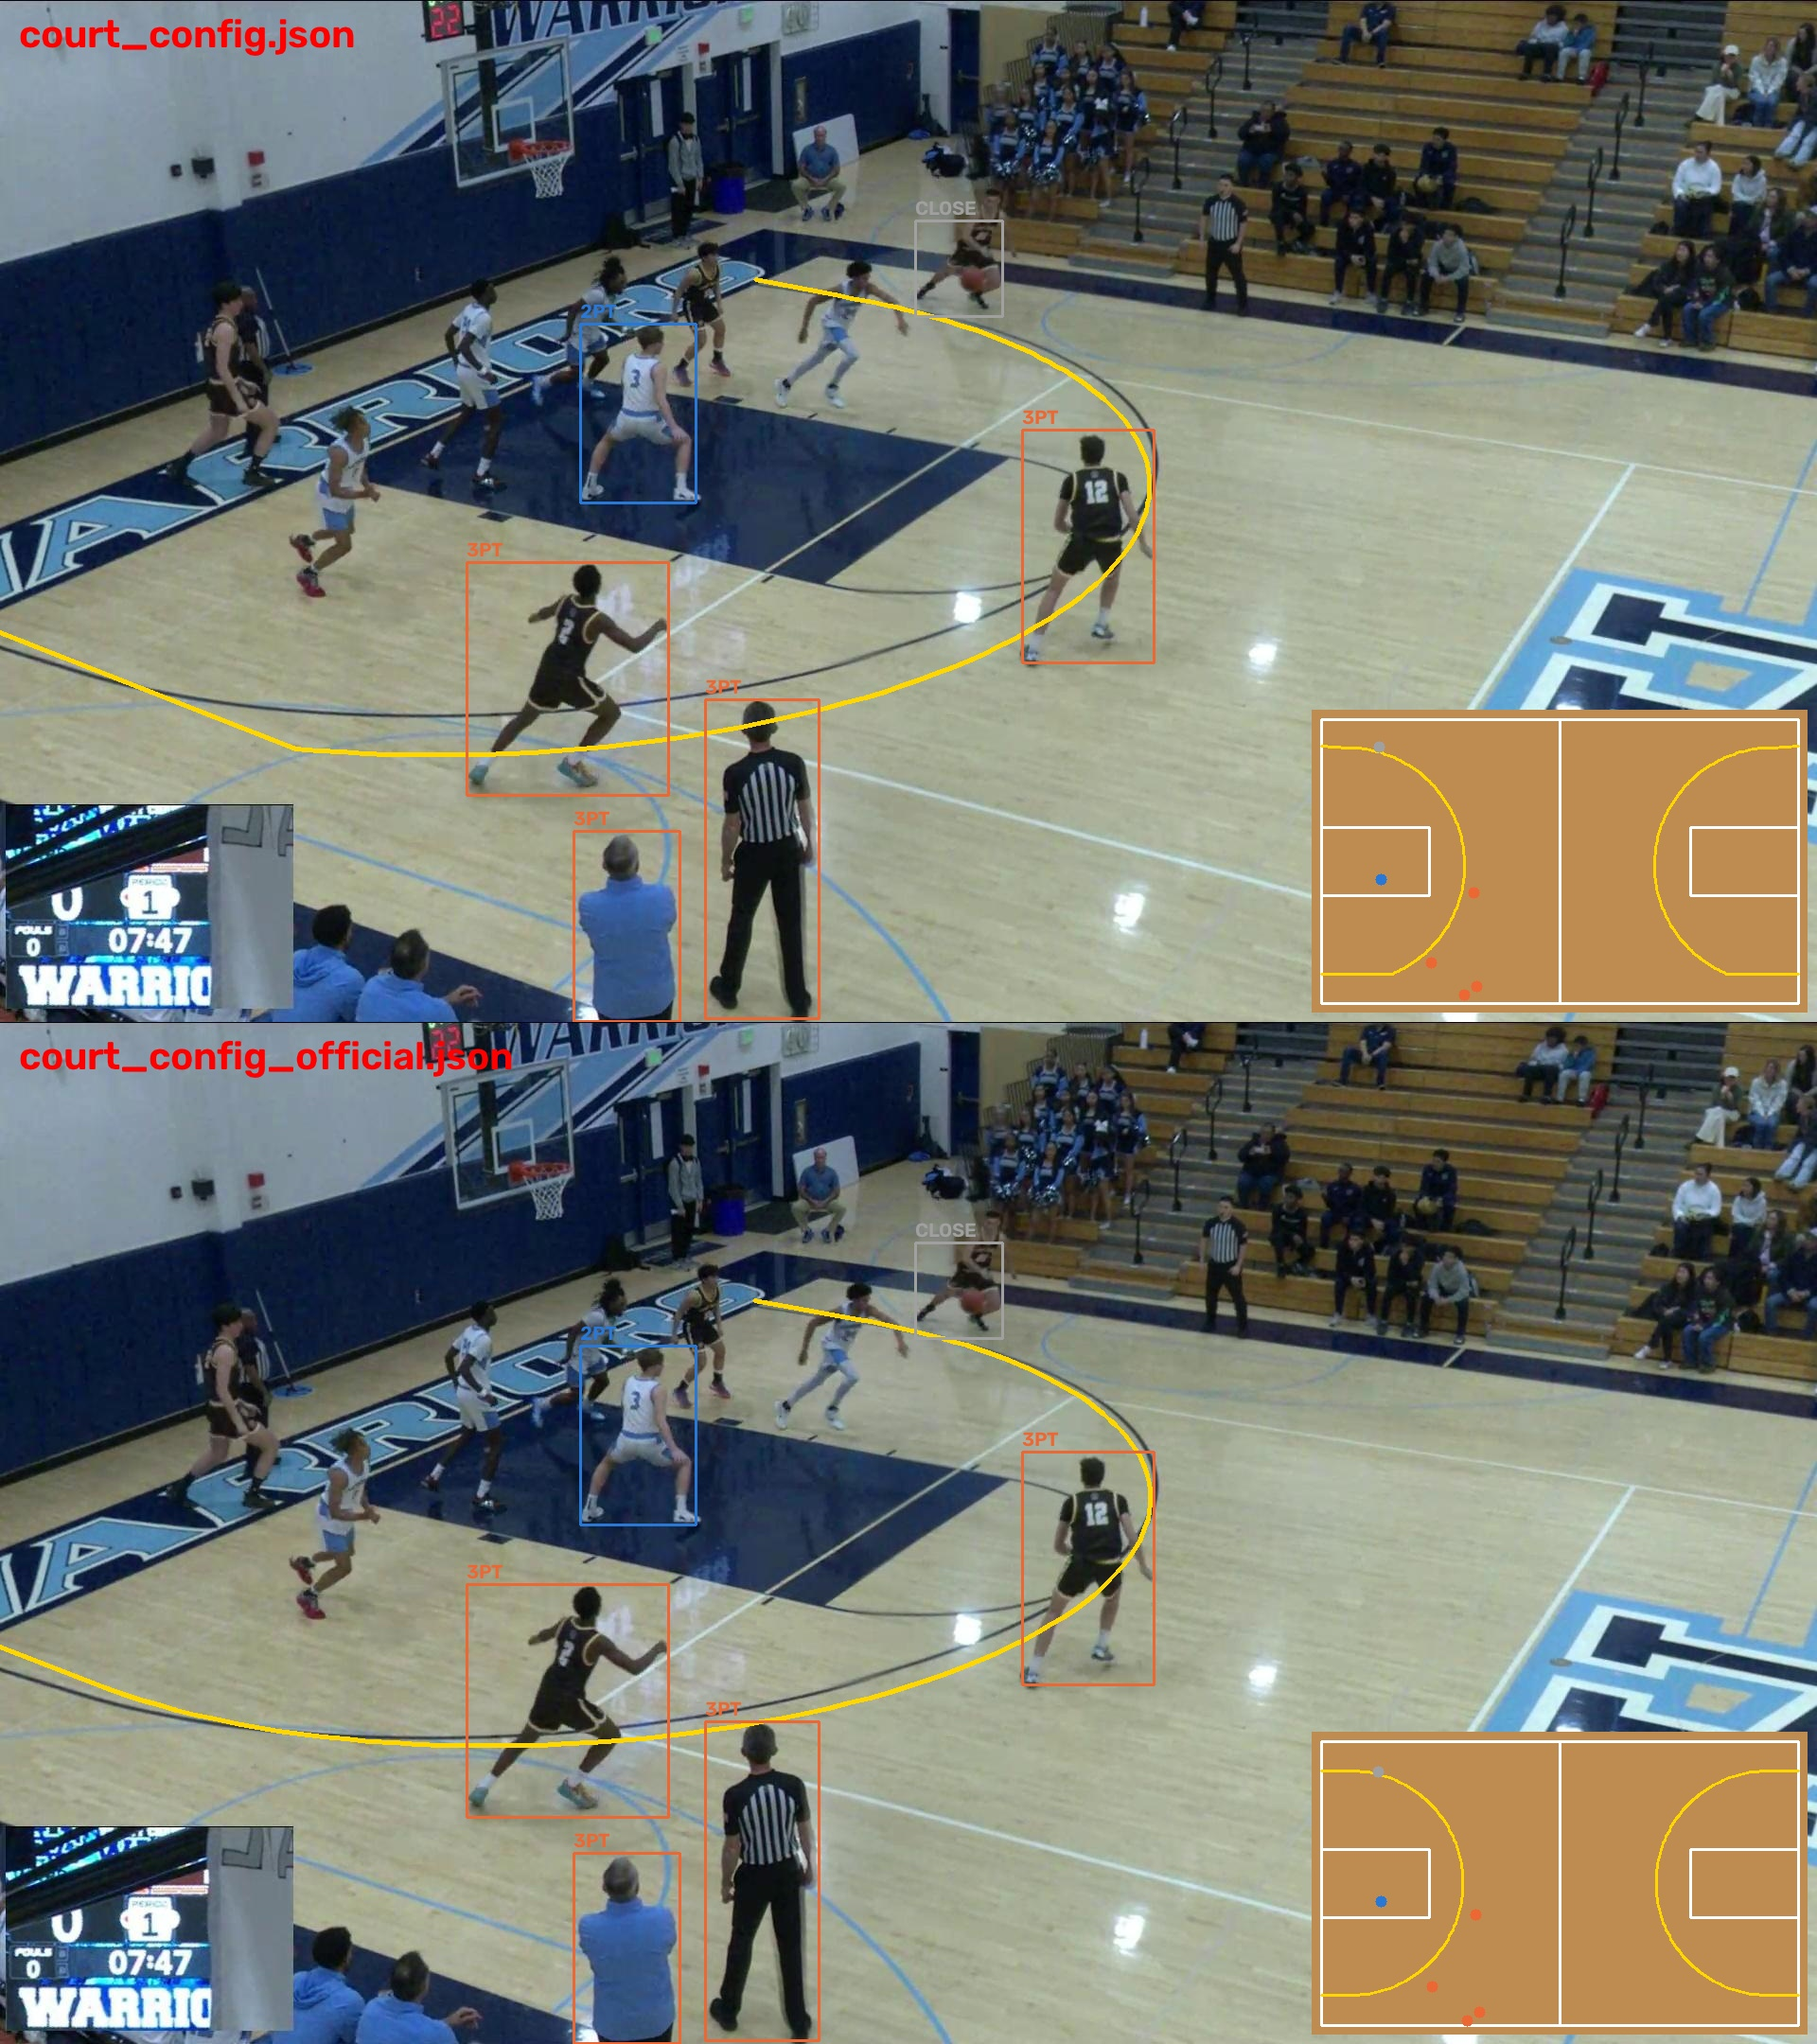

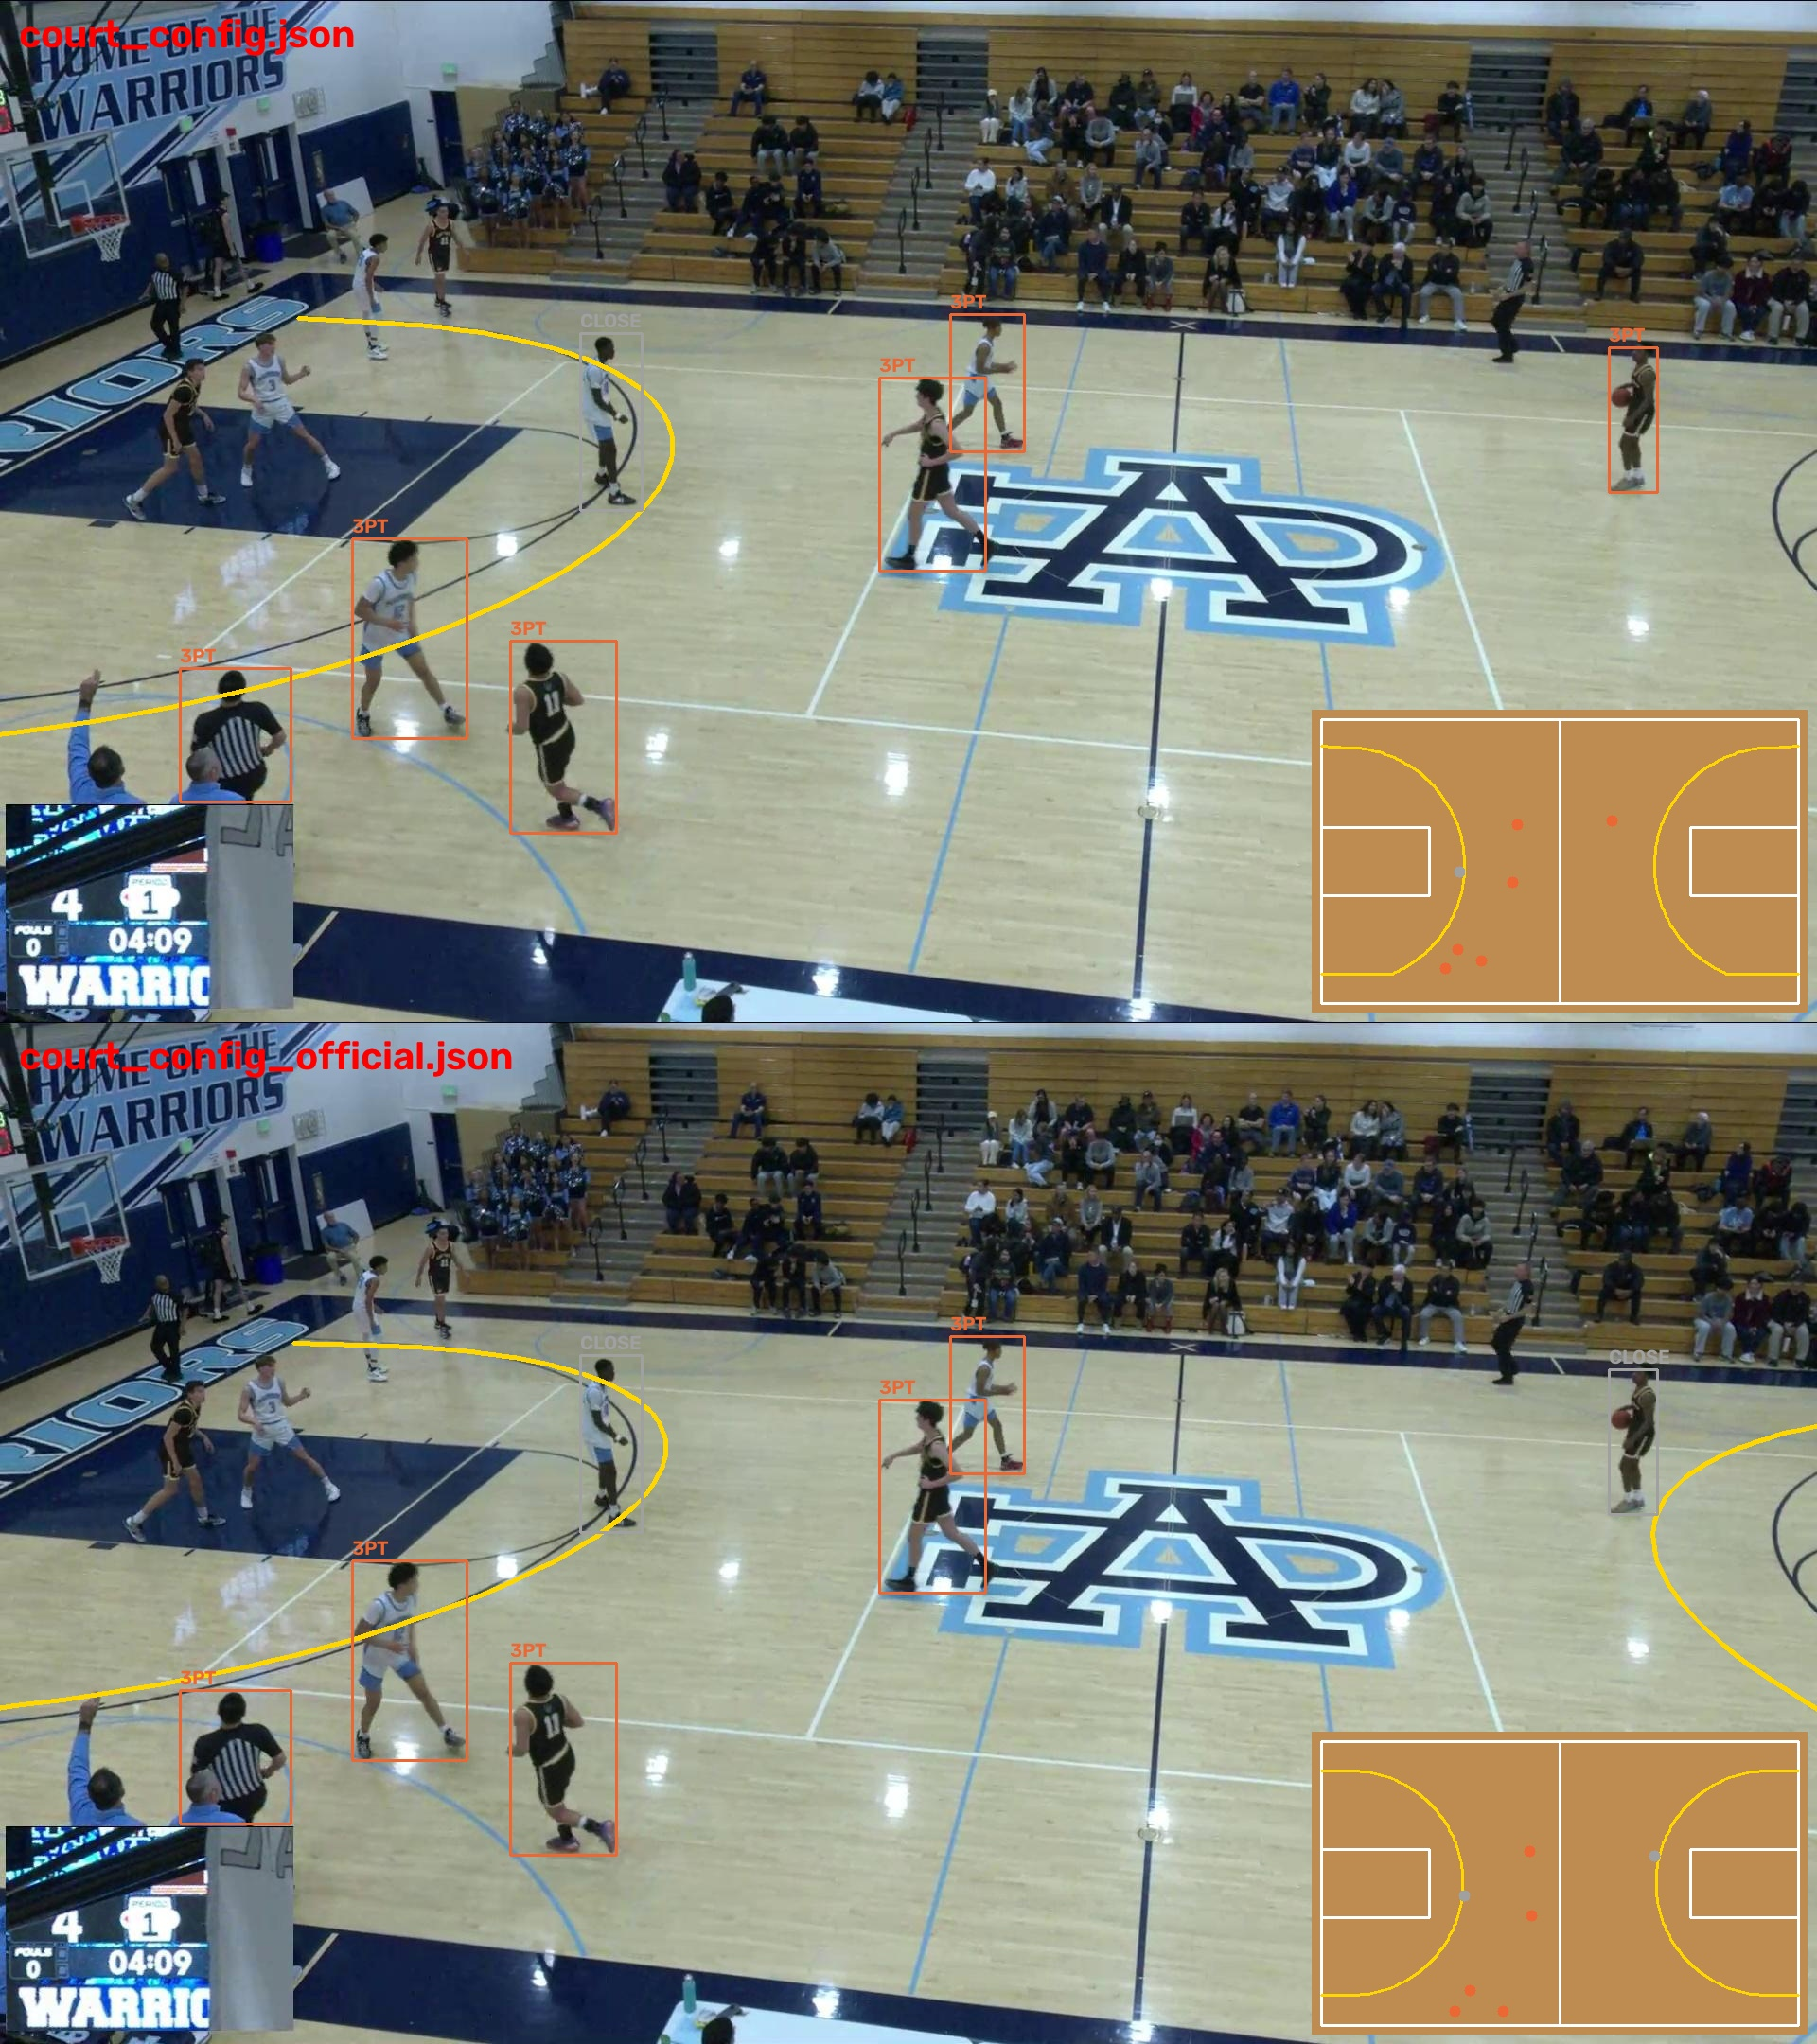

In [2]:
# ===== Fix 1: official 3-point geometry (one cell, safe on a fresh runtime) =====
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')
import os, sys, json, glob, random, cv2, numpy as np
from IPython.display import Image, display

PROJECT_DIR = '/content/drive/MyDrive/court_keypoints'
U   = f'{PROJECT_DIR}/court_unified'
REL = f'{PROJECT_DIR}/court_detection_release'
os.chdir(REL); sys.path.insert(0, REL)
from court_detector import CourtDetector
import demo
from ultralytics import YOLO

# ---- 1. Write two new configs next to the old one ----
HX, HY, R, L = 25.0, 5.25, 19.75, 84.0           # official high-school court: hoop center, 3-pt radius
old = json.load(open('court_config.json'))

# (a) "official": every point at its official spot
kp = {0: (0, 0), 1: (HX - R, 0), 2: (19, 0), 3: (31, 0), 4: (HX + R, 0), 5: (50, 0),
      6: (19, 19), 7: (31, 19), 8: (0, 42), 9: (50, 42)}
for i in (18, 19, 20):                             # arc points: same angle, moved onto the official circle
    x, y = old['keypoints_ft'][str(i)]
    a = np.arctan2(y - HY, x - HX)
    kp[i] = (HX + R * np.cos(a), HY + R * np.sin(a))
for i in range(8):
    kp[i + 10] = (kp[i][0], L - kp[i][1])          # right basket = mirror of the left
for i in (18, 19, 20):
    kp[i + 3] = (kp[i][0], L - kp[i][1])
official = json.loads(json.dumps(old))
official['keypoints_ft'] = {str(i): [float(x), float(y)] for i, (x, y) in sorted(kp.items())}
official['three_point'] = {'center': [HX, HY], 'radius': R, 'corner_x': [HX - R, HX + R]}
json.dump(official, open('court_config_official.json', 'w'), indent=2)

# (b) "line only": keep the old homography points, only draw the official 3-point line
line_only = json.loads(json.dumps(old))
line_only['three_point'] = official['three_point']
json.dump(line_only, open('court_config_lineonly.json', 'w'), indent=2)
print('Wrote court_config_official.json and court_config_lineonly.json')

# ---- 2. Compare the three configs on the VALIDATION images ----
CONFIGS = ['court_config.json', 'court_config_official.json', 'court_config_lineonly.json']
dets = {c: CourtDetector('weights/court_model.pt', c) for c in CONFIGS}
PAINT = {2: (19, 0), 3: (31, 0), 6: (19, 19), 7: (31, 19), 12: (19, 84), 13: (31, 84), 16: (19, 65), 17: (31, 65)}
LINE_IDS = [1, 4, 11, 14, 18, 19, 20, 21, 22, 23]  # labeled points that sit ON the 3-point line

def H_from(det, xy, kc):
    ids = [i for i in det.use_ids if i in det.kp_ft and kc[i] > det.conf_th]
    if len(ids) < 4:
        return None
    H, _ = cv2.findHomography(np.float32([xy[i] for i in ids]),
                              np.float32([det.kp_ft[i] for i in ids]), cv2.RANSAC, 1.5)
    return H

imgs = sorted(glob.glob(f'{U}/valid/images/*'))
res = {(c, g): {'paint': [], 'line': []} for c in CONFIGS for g in ('old', 'new')}
for p in imgs:
    g = 'new' if os.path.basename(p).startswith('new') else 'old'
    img = cv2.imread(p); h, w = img.shape[:2]
    xy, kc = dets[CONFIGS[0]].keypoints(img)      # the model is the same for every config: run it once
    if xy is None:
        continue
    lbl = p.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    v = [float(x) for x in open(lbl).readline().split()[5:]]
    for c, det in dets.items():
        H = H_from(det, xy, kc)
        if H is None:
            continue
        for i, ft in PAINT.items():                # how far off the paint corners land (same truth for all)
            if v[3*i+2] > 0:
                res[(c, g)]['paint'].append(np.hypot(*(det.to_court(H, [(v[3*i]*w, v[3*i+1]*h)])[0] - ft)))
        for i in LINE_IDS:                         # how far the drawn line is from the painted line
            if v[3*i+2] > 0:
                x, y = det.to_court(H, [(v[3*i]*w, v[3*i+1]*h)])[0]
                res[(c, g)]['line'].append(abs(det.distance_to_three_point_line(x, y)))

print(f'\n{len(imgs)} validation images.  Median error in feet (smaller = better)')
print(f"{'config':32s}{'group':>6s}{'paint':>8s}{'3pt line':>10s}")
for (c, g), r in res.items():
    if r['paint'] or r['line']:
        f = lambda a: f'{np.median(a):.2f}' if a else '  -'
        print(f"{c:32s}{g:>6s}{f(r['paint']):>8s}{f(r['line']):>10s}")

# ---- 3. Side-view pictures: OLD (top) vs OFFICIAL (bottom) ----
person = YOLO('yolo11n.pt')
random.seed(0)
for k, src in enumerate(random.sample(sorted(glob.glob(f'{U}/test_new/images/*')), 2)):
    frame = cv2.imread(src)
    xy, kc = dets[CONFIGS[0]].keypoints(frame)
    rows = []
    for c in ('court_config.json', 'court_config_official.json'):
        H = H_from(dets[c], xy, kc) if xy is not None else None
        out = demo.annotate(frame, dets[c], H, person)
        cv2.putText(out, c, (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.4, (0, 0, 255), 3)
        rows.append(out)
    cv2.imwrite(f'/content/compare_{k}.jpg', np.vstack(rows))
    display(Image(f'/content/compare_{k}.jpg', width=900))

In [3]:
import shutil; shutil.copy('court_config_lineonly.json', 'court_config.json'); print('done')

done
